<a href="https://colab.research.google.com/github/esubalewmilam-hue/MIS433/blob/main/Customer%20Churn%20Comp.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

For this project, I used customer account, demographic, and service data to predict whether a customer would leave the company. Churn = 1 means the customer left, and Churn = 0 means the customer stayed. I compared logistic regression, random forest, and gradient boosting.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

# Set the folder containing your CSV files
%cd "/content/drive/MyDrive/Colab Notebooks"

Mounted at /content/drive
/content/drive/MyDrive/Colab Notebooks


In [ ]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay
from sklearn.inspection import permutation_importance
from sklearn.base import clone
SEED = 42
OUT = Path('outputs')
OUT.mkdir(exist_ok=True)
print('Python:', sys.version.split()[0], '| pandas:', pd.__version__, '| sklearn:', sklearn.__version__)
DATA = next((p for p in [Path('.'), Path('data'), Path('upload'), Path('../upload')] if (p / 'churn_train.csv').exists()), None)
if DATA is None:
    raise FileNotFoundError('Place the six supplied CSV files in the notebook folder or data/ folder.')
names = ['accounts', 'demographics', 'services', 'churn_train', 'churn_test', 'sample_submission']
files = {name: pd.read_csv(DATA / (name + '.csv')) for name in names}
display(pd.DataFrame([{'File': name, 'Rows': len(df), 'Columns': len(df.columns), 'Missing cells': int(df.isna().sum().sum()), 'Duplicate rows': int(df.duplicated().sum())} for name, df in files.items()]))
for name, df in files.items():
    print('\n', name, ':', ', '.join(df.columns))
    display(df.head(3))

Python: 3.13.18 | pandas: 2.2.3 | sklearn: 1.6.1


,File,Rows,Columns,Missing cells,Duplicate rows
0,accounts,5298,8,15,0
1,demographics,5298,8,14,0
2,services,47682,3,0,0
3,churn_train,4238,2,0,0
4,churn_test,1060,1,0,0
5,sample_submission,1060,2,0,0



 accounts : CustomerNo, BaseCharges, DOC, TotalCharges, DOE, ElectronicBilling, ContractType, PaymentMethod


,CustomerNo,BaseCharges,DOC,TotalCharges,DOE,ElectronicBilling,ContractType,PaymentMethod
0,1201,478.50,5-1-2012,5920.00,10-Jan-11,No,One year,Electronic check
1,1202,103.25,5-1-2012,103.25,6-Dec-11,No,Month-to-month,Electronic check
2,1203,399.75,5-1-2012,5217.00,10-Jan-11,Yes,Month-to-month,Bank transfer (automatic)



 demographics : CustomerNo, Country, State, Retired, HasPartner, HasDependents, Education, Gender


,CustomerNo,Country,State,Retired,HasPartner,HasDependents,Education,Gender
0,1201,India,Maharashtra,0,2,2,Masters,Male
1,1202,India,Maharashtra,0,2,2,ProfessionalQalification,Male
2,1203,India,Maharashtra,0,2,2,ProfessionalQalification,Male


... (4 outputs left out)


 churn_test : CustomerNo


,CustomerNo
0,1203
1,1204
2,1208



 sample_submission : CustomerNo, Churn


,CustomerNo,Churn
0,1203,0
1,1204,0
2,1208,0


## Combining the data
The services file has several rows for each customer. I used a pivot to put each service in its own column. Then I joined the files using CustomerNo. I checked for duplicate customers and missing values. CustomerNo was used to match the records, but it was not used to predict churn.

In [ ]:
accounts = files['accounts'].copy()
demographics = files['demographics'].copy()
services = files['services'].copy()
assert not services.duplicated(['CustomerNo', 'TypeOfService']).any()
services_wide = services.pivot(index='CustomerNo', columns='TypeOfService', values='SeviceDetails').reset_index()
services_wide.columns.name = None
customers = accounts.merge(demographics, on='CustomerNo', validate='one_to_one').merge(services_wide, on='CustomerNo', validate='one_to_one')
for name in ['accounts', 'demographics', 'churn_train', 'churn_test', 'sample_submission']:
    assert files[name]['CustomerNo'].is_unique
assert len(customers) == len(accounts) == len(demographics)
assert set(files['churn_train'].CustomerNo).isdisjoint(set(files['churn_test'].CustomerNo))
assert set(customers.CustomerNo) == set(files['churn_train'].CustomerNo) | set(files['churn_test'].CustomerNo)
train = files['churn_train'].merge(customers, on='CustomerNo', how='left', validate='one_to_one')
test = files['churn_test'].merge(customers, on='CustomerNo', how='left', validate='one_to_one')
assert set(train.Churn.unique()) == {0, 1}
print('Integrated training shape:', train.shape, '| test shape:', test.shape)
display(train.dtypes.rename('Data type').to_frame())
display(train.isna().sum().loc[lambda x: x > 0].rename('Missing values').to_frame())

Integrated training shape: (4238, 25) | test shape: (1060, 24)


,Data type
CustomerNo,int64
Churn,int64
BaseCharges,float64
DOC,object
TotalCharges,float64
DOE,object
ElectronicBilling,object
ContractType,object
PaymentMethod,object
Country,object


,Missing values
TotalCharges,8
ContractType,3
Education,9
Gender,2


## Preparing the data
I calculated TenureMonths to show how long each customer had been with the company. I treated DOC as the observation date and read 5-1-2012 as January 5, 2012. The files do not explain this date, so this is an assumption. I also assumed TotalCharges was available at that time.

I converted the charge columns to numbers and treated the demographic codes as categories. I left out CustomerNo, the original date columns, Country, and State. Country and State each have two unique values; they are not constant columns.

In [ ]:
def prepare_features(df):
    result = df.copy()
    cutoff = pd.to_datetime(result['DOC'], format='%d-%m-%Y', errors='coerce')
    entry = pd.to_datetime(result['DOE'], format='%d-%b-%y', errors='coerce')
    tenure = (cutoff - entry).dt.days / 30.4375
    result['TenureMonths'] = tenure.where(tenure >= 0)
    for col in ['BaseCharges', 'TotalCharges']:
        result[col] = pd.to_numeric(result[col], errors='coerce')
    for col in ['Retired', 'HasPartner', 'HasDependents']:
        result[col] = result[col].astype(str)
    return result.drop(columns=['CustomerNo', 'Churn', 'DOC', 'DOE', 'Country', 'State'], errors='ignore')
X = prepare_features(train)
y = train['Churn'].astype(int)
X_test = prepare_features(test)
print('Predictors:', list(X.columns))
print('Invalid or missing tenure:', X.TenureMonths.isna().sum())
print('Country and State unique counts:', train[['Country', 'State']].nunique().to_dict())
display(X.describe().round(2))
display(X.describe(include='object').T)
display(y.value_counts().sort_index().rename_axis('Churn').to_frame('Count'))
print('Churn rate:', round(y.mean(), 4))

Predictors: ['BaseCharges', 'TotalCharges', 'ElectronicBilling', 'ContractType', 'PaymentMethod', 'Retired', 'HasPartner', 'HasDependents', 'Education', 'Gender', 'DeviceProtection', 'HasPhoneService', 'InternetServiceCategory', 'MultipleLines', 'OnlineBackup', 'OnlineSecurity', 'StreamingMovies', 'StreamingTelevision', 'TechnicalSupport', 'TenureMonths']
Invalid or missing tenure: 0
Country and State unique counts: {'Country': 2, 'State': 2}


,BaseCharges,TotalCharges,TenureMonths
count,4238.00,4230.00,4238.00
mean,325.91,11927.02,33.20
std,151.17,11514.25,24.31
min,91.25,94.25,0.00
25%,183.50,2286.75,9.86
50%,352.38,7457.62,30.55
75%,452.00,19966.12,56.18
max,593.75,43362.25,70.97


,count,unique,top,freq
ElectronicBilling,4238,2,Yes,2521
ContractType,4235,3,Month-to-month,2235
PaymentMethod,4238,4,Electronic check,1270
Retired,4238,2,0,3574
HasPartner,4238,2,2,2132
HasDependents,4238,2,2,2937
Education,4229,5,Highschool or below,1145
Gender,4236,2,Male,2131
DeviceProtection,4238,3,No,1822
HasPhoneService,4238,2,1,3818


,Count
Churn,
0,3189
1,1049


Churn rate: 0.2475


## Exploring the data
I looked at customer counts, churn rates, contract types, tenure, and charges. The charts and tables below show how customers who left differ from customers who stayed. These patterns show relationships, but they do not prove what caused customers to leave.

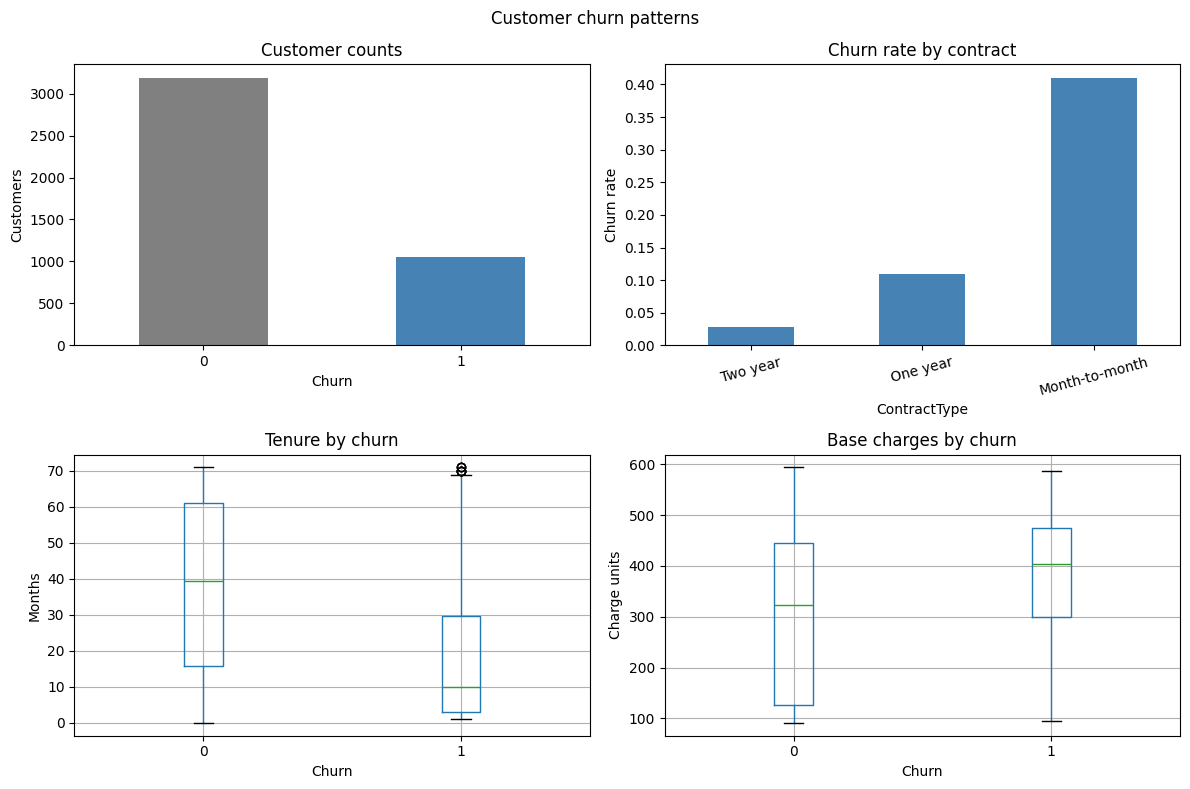

ContractType


,Customers,ChurnRate
ContractType,,
Month-to-month,2235,0.410
One year,919,0.110
Two year,1081,0.028


InternetServiceCategory


,Customers,ChurnRate
InternetServiceCategory,,
DSL,1479,0.171
Fiber optic,1853,0.399
No,906,0.062


PaymentMethod


,Customers,ChurnRate
PaymentMethod,,
Bank transfer (automatic),904,0.169
Credit card (automatic),1231,0.152
Electronic check,1270,0.442
Mailed check,833,0.178


,TenureMonths,BaseCharges,TotalCharges
Churn,,,
0,38.04,308.68,13197.68
1,18.47,378.30,8073.86


In [ ]:
eda = X.assign(Churn=y)
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
y.value_counts().sort_index().plot.bar(ax=axes[0,0], color=['gray', 'steelblue'], rot=0)
axes[0,0].set(title='Customer counts', xlabel='Churn', ylabel='Customers')
eda.groupby('ContractType').Churn.mean().sort_values().plot.bar(ax=axes[0,1], color='steelblue', rot=15)
axes[0,1].set(title='Churn rate by contract', ylabel='Churn rate')
eda.boxplot(column='TenureMonths', by='Churn', ax=axes[1,0])
axes[1,0].set(title='Tenure by churn', ylabel='Months')
eda.boxplot(column='BaseCharges', by='Churn', ax=axes[1,1])
axes[1,1].set(title='Base charges by churn', ylabel='Charge units')
fig.suptitle('Customer churn patterns')
plt.tight_layout()
plt.savefig(OUT / 'eda.png', dpi=160)
plt.show()
for col in ['ContractType', 'InternetServiceCategory', 'PaymentMethod']:
    print(col)
    display(eda.groupby(col).Churn.agg(Customers='size', ChurnRate='mean').round(3))
display(eda.groupby('Churn')[['TenureMonths', 'BaseCharges', 'TotalCharges']].mean().round(2))

## Building the models
I used 80% of the labeled data to train the models and saved 20% to check their predictions. The split kept a similar percentage of churners in both groups. I used random_state = 42 so the split could be repeated.

Missing numbers were filled with the median. Missing categories were filled with the most common value. Categories were changed into numeric columns using one-hot encoding. Numeric columns were scaled so larger numbers would not have more influence just because of their size. These steps were learned from the training data only.

I compared three models:
- **Logistic regression:** predicts the chance that a customer will churn. I used C = 1 and max_iter = 2000.
- **Random forest:** combines many decision trees. I used 400 trees, at least 3 records per leaf, and max_features = 'sqrt'.
- **Gradient boosting:** builds trees that improve on earlier predictions. I used 200 iterations, a learning rate of 0.05, up to 15 leaves, at least 20 records per leaf, and an L2 penalty of 1.

All three models used the same input columns and data preparation steps. A churn probability of 0.5 or higher was classified as churn.

I used five-fold cross-validation on the training portion to compare the models. This trains and checks each model across five different splits. I selected the model with the highest average accuracy.

In [ ]:
X_fit, X_valid, y_fit, y_valid = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
numeric = X.select_dtypes(include='number').columns.tolist()
categorical = X.select_dtypes(exclude='number').columns.tolist()
preprocessing = ColumnTransformer([
    ('numeric', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scale', StandardScaler())]), numeric),
    ('categorical', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('encode', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), categorical)
])
models = {
    'LogisticRegression': LogisticRegression(C=1.0, max_iter=2000, random_state=SEED),
    'RandomForest': RandomForestClassifier(n_estimators=400, min_samples_leaf=3, max_features='sqrt', random_state=SEED, n_jobs=2),
    'GradientBoosting': HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05, max_leaf_nodes=15, min_samples_leaf=20, l2_regularization=1.0, random_state=SEED)
}
pipelines = {name: Pipeline([('preprocess', clone(preprocessing)), ('model', model)]) for name, model in models.items()}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
rows = []
for name, pipeline in pipelines.items():
    scores = cross_validate(pipeline, X_fit, y_fit, cv=cv, scoring=['accuracy', 'f1', 'roc_auc'], n_jobs=1)
    rows.append({'Model': name, 'CV_accuracy': scores['test_accuracy'].mean(), 'CV_accuracy_sd': scores['test_accuracy'].std(), 'CV_F1': scores['test_f1'].mean(), 'CV_ROC_AUC': scores['test_roc_auc'].mean()})
cv_results = pd.DataFrame(rows).sort_values('CV_accuracy', ascending=False)
best_name = cv_results.iloc[0]['Model']
display(cv_results.round(4))
print('Model selected using cross-validation:', best_name)

,Model,CV_accuracy,CV_accuracy_sd,CV_F1,CV_ROC_AUC
0,LogisticRegression,0.8204,0.0104,0.5935,0.8599
1,RandomForest,0.8088,0.0133,0.5504,0.8494
2,GradientBoosting,0.8071,0.0091,0.5696,0.8490


Model selected using cross-validation: LogisticRegression


## Model results
I checked the models on the 20% of customers that were held out of training. Accuracy shows the percentage of correct predictions. Precision shows how many customers predicted to leave actually left. Recall shows how many actual churners the model found. F1 combines precision and recall. ROC AUC measures how well the model separates churners from customers who stay.

These are local validation results, not Kaggle scores. The model was selected using cross-validation before checking these results. Predicting that everyone stays is included only as a comparison, not as one of my three models.

,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,LogisticRegression,0.8373,0.7250,0.5524,0.6270,0.8720
1,RandomForest,0.8361,0.7591,0.4952,0.5994,0.8673
2,GradientBoosting,0.8337,0.7091,0.5571,0.6240,0.8711


Validation majority-class accuracy: 0.7524
Assignment Kaggle baseline: 0.71698


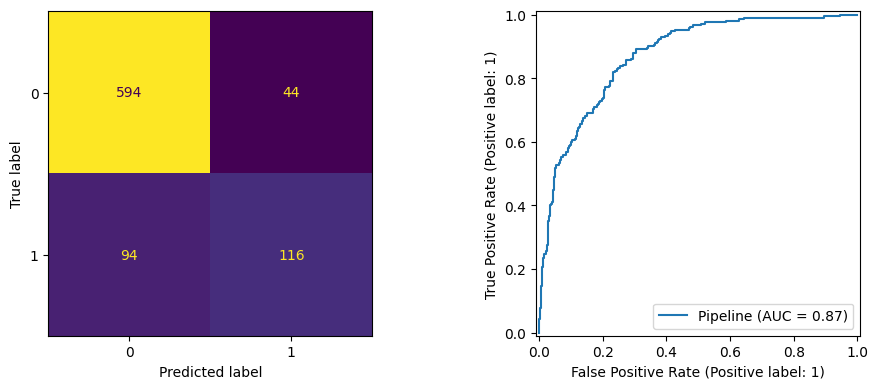

,Variable,Mean accuracy decrease
19,TenureMonths,0.1113
8,Education,0.0229
1,TotalCharges,0.0210
3,ContractType,0.0210
0,BaseCharges,0.0163
12,InternetServiceCategory,0.0106
4,PaymentMethod,0.0085
18,TechnicalSupport,0.0073
2,ElectronicBilling,0.0059
15,OnlineSecurity,0.0040


In [ ]:
rows = []
for name, pipeline in pipelines.items():
    pipeline.fit(X_fit, y_fit)
    predictions = pipeline.predict(X_valid)
    probabilities = pipeline.predict_proba(X_valid)[:, 1]
    rows.append({'Model': name, 'Accuracy': accuracy_score(y_valid, predictions), 'Precision': precision_score(y_valid, predictions, zero_division=0), 'Recall': recall_score(y_valid, predictions), 'F1': f1_score(y_valid, predictions), 'ROC_AUC': roc_auc_score(y_valid, probabilities)})
validation = pd.DataFrame(rows)
display(validation.round(4))
print('Validation majority-class accuracy:', round(y_valid.value_counts(normalize=True).max(), 4))
print('Assignment Kaggle baseline:', 0.71698)
selected = pipelines[best_name]
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay.from_estimator(selected, X_valid, y_valid, ax=axes[0], colorbar=False)
RocCurveDisplay.from_estimator(selected, X_valid, y_valid, ax=axes[1])
plt.tight_layout()
plt.savefig(OUT / 'validation.png', dpi=160)
plt.show()
importance = permutation_importance(selected, X_valid, y_valid, scoring='accuracy', n_repeats=5, random_state=SEED, n_jobs=1)
importance_table = pd.DataFrame({'Variable': X.columns, 'Mean accuracy decrease': importance.importances_mean}).sort_values('Mean accuracy decrease', ascending=False)
display(importance_table.head(10).round(4))
cv_results.to_csv(OUT / 'cross_validation_results.csv', index=False)
validation.to_csv(OUT / 'validation_results.csv', index=False)

## Churn predictions
I trained each model again using all 4,238 labeled customers and predicted churn for the 1,060 customers in the test file. The CSV files use the same columns and customer order as sample_submission.csv. The sample file was used for formatting, not as training labels.

Each model has its own prediction file. The submission.csv file contains the logistic regression predictions because that model had the highest cross-validation accuracy.

In [ ]:
sample = files['sample_submission']
assert set(sample.CustomerNo) == set(test.CustomerNo)
assert sample.columns.tolist() == ['CustomerNo', 'Churn']
for name, pipeline in pipelines.items():
    final_model = clone(pipeline).fit(X, y)
    prediction_map = pd.Series(final_model.predict(X_test).astype(int), index=test.CustomerNo)
    submission = sample[['CustomerNo']].copy()
    submission['Churn'] = submission.CustomerNo.map(prediction_map)
    assert not submission.isna().any().any()
    assert submission.CustomerNo.tolist() == sample.CustomerNo.tolist()
    assert set(submission.Churn.unique()).issubset({0, 1})
    assert len(submission) == 1060
    submission.to_csv(OUT / f'submission_{name}.csv', index=False)
    if name == best_name:
        submission.to_csv(OUT / 'submission.csv', index=False)
    print(name, ':', len(submission), 'rows;', int(submission.Churn.sum()), 'predicted churners')
print('Recommended submission.csv model:', best_name)

LogisticRegression : 1060 rows; 206 predicted churners
RandomForest : 1060 rows; 180 predicted churners
GradientBoosting : 1060 rows; 206 predicted churners
Recommended submission.csv model: LogisticRegression


results
Logistic regression had the highest average cross-validation accuracy at 82.04%. Its validation accuracy was 83.73%, compared with 83.61% for random forest and 83.37% for gradient boosting. The results were close, so there was not a large difference between the models.

Logistic regression had 72.50% precision and 55.24% recall. This means it found a little more than half of the customers who actually churned, even though its overall accuracy was fairly high.

Month-to-month customers had a churn rate of 41.03%, compared with 10.99% for one-year contracts and 2.78% for two-year contracts. Customers who churned had an average tenure of 18.47 months, while customers who stayed averaged 38.04 months. Tenure had the largest effect on accuracy when its values were shuffled in the importance check.

## Main takeaways
The results suggest that newer customers and customers with month-to-month contracts may be useful groups to focus on for retention. However, this analysis does not prove that a longer contract would stop a customer from leaving.

Logistic regression performed slightly better than the more complex models. I also found that accuracy alone does not show the full picture, because the model still missed many customers who churned.

The results come from one dataset and have not been checked on future customers. The date interpretation is an assumption, and actual Kaggle scores are not included in these results.